In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
train_dir = '/content/drive/MyDrive/FishQuality/train'
test_dir = '/content/drive/MyDrive/FishQuality/test'

In [ ]:
import os
print(len(os.listdir('/content/drive/MyDrive/FishQuality/train/Fresh')))
print(len(os.listdir('/content/drive/MyDrive/FishQuality/train/Spoilt')))
print(len(os.listdir('/content/drive/MyDrive/FishQuality/test/Fresh')))
print(len(os.listdir('/content/drive/MyDrive/FishQuality/test/Spoilt')))

400
400
100
100


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator


train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)


train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(256,256),
    batch_size=32,
    class_mode='binary',
    subset='training'
)


validation_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)


validation_data = validation_datagen.flow_from_directory(
    train_dir,
    target_size=(256,256),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

Found 640 images belonging to 2 classes.
Found 160 images belonging to 2 classes.


In [ ]:
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,BatchNormalization,UpSampling2D, Dropout

In [ ]:
model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))  # 32 filters
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [ ]:
from keras.optimizers import Adam
model.compile(optimizer=Adam(learning_rate=0.001),loss='binary_crossentropy',metrics=['accuracy'])

NameError: name 'model' is not defined

In [ ]:
history = model.fit(train_data, epochs=20, validation_data=validation_data)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 116s 7s/step - accuracy: 0.7636 - loss: 0.3625 - val_accuracy: 1.0000 - val_loss: 1.2485e-04
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 89s 5s/step - accuracy: 1.0000 - loss: 4.3280e-04 - val_accuracy: 1.0000 - val_loss: 5.5645e-06
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 89s 5s/step - accuracy: 1.0000 - loss: 2.1541e-06 - val_accuracy: 1.0000 - val_loss: 5.4788e-08
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 91s 6s/step - accuracy: 1.0000 - loss: 3.1398e-07 - val_accuracy: 1.0000 - val_loss: 1.8095e-08
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 88s 5s/step - accuracy: 1.0000 - loss: 3.5103e-07 - val_accuracy: 1.0000 - val_loss: 1.7925e-08
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 87s 5s/step - accuracy: 1.0000 - loss: 1.5168e-07 - val_accuracy: 1.0000 - val_loss: 2.1930e-08
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 100s 6s/step - accuracy: 1.0000 - loss: 1.6269e-07 - val_accuracy: 1.0000 - val_loss: 2.6253e-08
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 91s 6s/step - accuracy: 1.

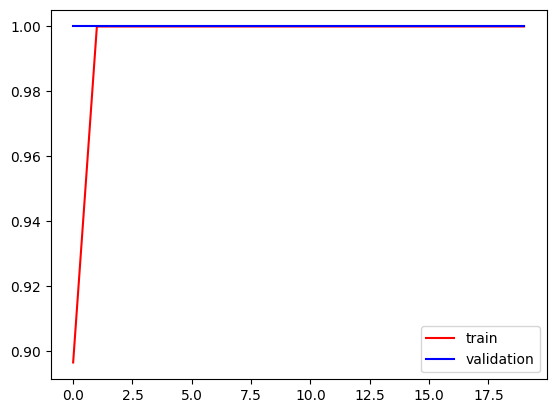

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

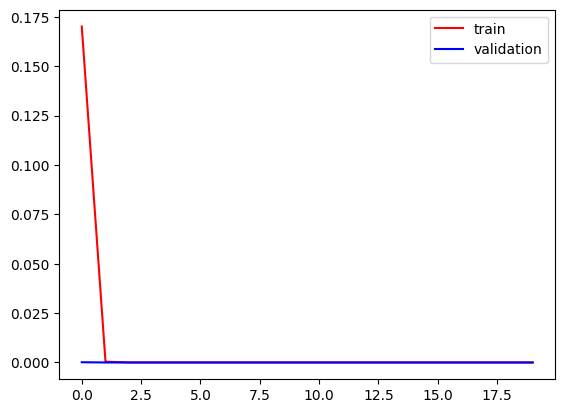

In [ ]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(256,256),
    batch_size=32,
    class_mode='binary'
)

Found 160 images belonging to 2 classes.


In [ ]:
#predict the test data
predictions = model.predict(test_data)

5/5 ━━━━━━━━━━━━━━━━━━━━ 30s 7s/step


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

true_labels = test_data.classes
predicted_labels = (predictions > 0.5).astype(int)

cm = confusion_matrix(true_labels, predicted_labels)

print("Confusion Matrix:")
print(cm)

print("Classification Report:")
print(classification_report(true_labels, predicted_labels))

Confusion Matrix:
[[36 44]
 [45 35]]
Classification Report:
              precision    recall  f1-score   support

           0       0.44      0.45      0.45        80
           1       0.44      0.44      0.44        80

    accuracy                           0.44       160
   macro avg       0.44      0.44      0.44       160
weighted avg       0.44      0.44      0.44       160



Now going to create and use another custom CNN Model for overcoming overfitting

In [ ]:
from tensorflow.keras import regularizers

# Clear any previous models
import tensorflow as tf
tf.keras.backend.clear_session()

# Create enhanced CNN model
model = Sequential()

# Input layer explicitly
model.add(tf.keras.layers.Input(shape=(256,256,3)))

# First Conv Block with more filters
model.add(Conv2D(64, kernel_size=(3,3), padding='same', activation='relu'))  # More filters
model.add(BatchNormalization())  # Normalization to help training
model.add(MaxPooling2D(pool_size=(2,2), strides=2))
model.add(Dropout(0.25))  # Regularization

# Second Conv Block
model.add(Conv2D(128, kernel_size=(3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2))
model.add(Dropout(0.25))

# Third Conv Block
model.add(Conv2D(256, kernel_size=(3,3), padding='same', activation='relu'))  # More filters
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2))
model.add(Dropout(0.25))

# Fourth Conv Block (additional)
model.add(Conv2D(512, kernel_size=(3,3), padding='same', activation='relu'))  # Even more filters
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2))
model.add(Dropout(0.25))

model.add(Flatten())

# Dense layers with regularization
model.add(Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.001)))  # L2 regularization
model.add(BatchNormalization())
model.add(Dropout(0.5))

model.add(Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
model.add(BatchNormalization())
model.add(Dropout(0.5))

model.add(Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
model.add(BatchNormalization())
model.add(Dropout(0.5))

model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer=Adam(learning_rate=0.001),loss='binary_crossentropy',metrics=['accuracy'])


In [ ]:
history = model.fit(train_data, epochs=20, validation_data=validation_data)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 460s 29s/step - accuracy: 1.0000 - loss: 1.9372 - val_accuracy: 0.9844 - val_loss: 1.9608
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 455s 28s/step - accuracy: 0.9970 - loss: 1.7778 - val_accuracy: 0.6641 - val_loss: 2.1281
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 457s 29s/step - accuracy: 1.0000 - loss: 1.6236 - val_accuracy: 0.5547 - val_loss: 2.2734
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 460s 29s/step - accuracy: 1.0000 - loss: 1.4809 - val_accuracy: 0.5156 - val_loss: 2.5591
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 459s 29s/step - accuracy: 1.0000 - loss: 1.3535 - val_accuracy: 0.5078 - val_loss: 2.7044
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 458s 29s/step - accuracy: 1.0000 - loss: 1.2433 - val_accuracy: 0.5156 - val_loss: 2.3829
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 471s 30s/step - accuracy: 1.0000 - loss: 1.1448 - val_accuracy: 0.5000 - val_loss: 2.4020
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 471s 30s/step - accuracy: 1.0000 - loss: 1.0549 - val_accuracy: 0.

In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(256,256),
    batch_size=32,
    class_mode='binary'
)

Found 160 images belonging to 2 classes.


In [ ]:
predictions = model.predict(test_data)

5/5 ━━━━━━━━━━━━━━━━━━━━ 46s 9s/step


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

true_labels = test_data.classes
predicted_labels = (predictions > 0.5).astype(int)

cm = confusion_matrix(true_labels, predicted_labels)

print("Confusion Matrix:")
print(cm)

print("Classification Report after applying techniques to handle overfitting:")
print(classification_report(true_labels, predicted_labels))

Confusion Matrix:
[[36 44]
 [46 34]]
Classification Report after applying techniques to handle overfitting:
              precision    recall  f1-score   support

           0       0.44      0.45      0.44        80
           1       0.44      0.42      0.43        80

    accuracy                           0.44       160
   macro avg       0.44      0.44      0.44       160
weighted avg       0.44      0.44      0.44       160



**Pretrained models ResNet**

In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Flatten, Dropout, BatchNormalization

tf.keras.backend.clear_session()

resnet_model = Sequential()

pretrained_model = tf.keras.applications.ResNet50(
    include_top=False,
    input_shape=(256, 256, 3),
    pooling='avg',
    weights='imagenet'
)

for layer in pretrained_model.layers:
    layer.trainable = False

resnet_model.add(pretrained_model)
resnet_model.add(Flatten())


resnet_model.add(Dense(512, activation='relu'))
resnet_model.add(BatchNormalization())
resnet_model.add(Dropout(0.5))

resnet_model.add(Dense(256, activation='relu'))
resnet_model.add(BatchNormalization())
resnet_model.add(Dropout(0.5))

resnet_model.add(Dense(128, activation='relu'))
resnet_model.add(BatchNormalization())
resnet_model.add(Dropout(0.5))

resnet_model.add(Dense(1, activation='sigmoid'))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
from keras.optimizers import Adam
resnet_model.compile(optimizer=Adam(learning_rate=0.001),loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
history = resnet_model.fit(train_data, epochs=20, validation_data=validation_data)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 210s 12s/step - accuracy: 0.7488 - loss: 0.5373 - val_accuracy: 0.5000 - val_loss: 0.6672
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 197s 12s/step - accuracy: 0.9584 - loss: 0.0986 - val_accuracy: 0.5000 - val_loss: 1.3960
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 195s 12s/step - accuracy: 0.9790 - loss: 0.0557 - val_accuracy: 0.5000 - val_loss: 1.9829
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 188s 12s/step - accuracy: 0.9825 - loss: 0.0413 - val_accuracy: 0.5000 - val_loss: 2.0974
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 187s 12s/step - accuracy: 0.9826 - loss: 0.0642 - val_accuracy: 0.5000 - val_loss: 2.1334
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 190s 12s/step - accuracy: 0.9965 - loss: 0.0172 - val_accuracy: 0.5000 - val_loss: 2.0254
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 189s 12s/step - accuracy: 0.9940 - loss: 0.0232 - val_accuracy: 0.5000 - val_loss: 1.8941
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 185s 12s/step - accuracy: 0.9977 - loss: 0.0125 - val_accuracy: 0.

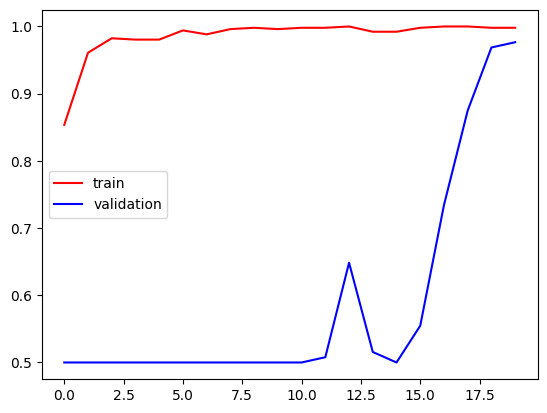

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

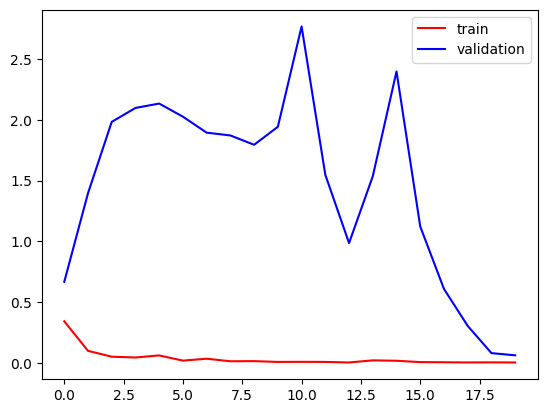

In [ ]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(256,256),
    batch_size=32,
    class_mode='binary'
)

Found 160 images belonging to 2 classes.


In [ ]:
#predict the test data
predictions = model.predict(test_data)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


5/5 ━━━━━━━━━━━━━━━━━━━━ 35s 7s/step


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

true_labels = test_data.classes
predicted_labels = (predictions > 0.5).astype(int)

cm = confusion_matrix(true_labels, predicted_labels)

print("Confusion Matrix:")
print(cm)

print("Classification Report:")
print(classification_report(true_labels, predicted_labels))

Confusion Matrix:
[[39 41]
 [43 37]]
Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.49      0.48        80
           1       0.47      0.46      0.47        80

    accuracy                           0.47       160
   macro avg       0.47      0.47      0.47       160
weighted avg       0.47      0.47      0.47       160



**Pre-trained Model EfficientNetBO**

new validation has to be made as EfficientNetBO model has a few changes

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

# Training generator with EfficientNet-specific preprocessing
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rescale=1./255,
    validation_split=0.2
)

# Load and prepare training data
train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(256, 256),
    batch_size=32,
    class_mode='binary',
    subset='training',
    shuffle=True,
    seed=42
)

# Validation generator (same preprocessing, no augmentation)
validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rescale=1./255,
    validation_split=0.2
)

validation_data = validation_datagen.flow_from_directory(
    train_dir,
    target_size=(256, 256),
    batch_size=32,
    class_mode='binary',
    subset='validation',
    shuffle=False
)


Found 512 images belonging to 2 classes.
Found 128 images belonging to 2 classes.


In [ ]:

import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Flatten

print("=== Building Simple EfficientNetB0 Model ===")

tf.keras.backend.clear_session()

efficientnet_model = Sequential()

pretrained_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    input_shape=(256, 256, 3),
    pooling='avg',
    weights='imagenet'
)


for layer in pretrained_model.layers:
    layer.trainable = False


efficientnet_model.add(pretrained_model)


efficientnet_model.add(Flatten())


efficientnet_model.add(Dense(128, activation='relu'))


efficientnet_model.add(Dense(1, activation='sigmoid'))

print("✅ EfficientNetB0 model created successfully!")

=== Building Simple EfficientNetB0 Model ===
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ EfficientNetB0 model created successfully!


In [ ]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = efficientnet_model.fit(train_data, epochs=20, validation_data=validation_data)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 96s 5s/step - accuracy: 0.4933 - loss: 0.7199 - val_accuracy: 0.5000 - val_loss: 0.7462
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 80s 5s/step - accuracy: 0.5038 - loss: 0.7276 - val_accuracy: 0.5000 - val_loss: 0.6956
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 76s 5s/step - accuracy: 0.5231 - loss: 0.6979 - val_accuracy: 0.5000 - val_loss: 0.6971
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 81s 5s/step - accuracy: 0.4746 - loss: 0.7060 - val_accuracy: 0.5000 - val_loss: 0.6971
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 76s 5s/step - accuracy: 0.5269 - loss: 0.7168 - val_accuracy: 0.5000 - val_loss: 0.7237
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 77s 5s/step - accuracy: 0.4789 - loss: 0.7155 - val_accuracy: 0.5000 - val_loss: 0.7094
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 75s 5s/step - accuracy: 0.4319 - loss: 0.7185 - val_accuracy: 0.5000 - val_loss: 0.6981
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 76s 5s/step - accuracy: 0.5448 - loss: 0.6886 - val_accuracy: 0.5000 - val_loss:

In [ ]:
predictions = efficientnet_model.predict(test_data)

5/5 ━━━━━━━━━━━━━━━━━━━━ 24s 4s/step


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report


true_labels = test_data.classes
predicted_labels = (predictions > 0.5).astype(int)

cm = confusion_matrix(true_labels, predicted_labels)


print("Confusion Matrix:")
print(cm)


print("Classification Report:")
print(classification_report(true_labels, predicted_labels))

Confusion Matrix:
[[ 0 80]
 [ 0 80]]
Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        80
           1       0.50      1.00      0.67        80

    accuracy                           0.50       160
   macro avg       0.25      0.50      0.33       160
weighted avg       0.25      0.50      0.33       160



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


The above is EfficientNetBO. Leaving it aside for time being

**Using New Pretrained Model MobileNetV2**

In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Flatten
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

In [ ]:

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rescale=1./255,
    validation_split=0.2
)

train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),  # MobileNetV2 expects 224x224
    batch_size=32,
    class_mode='binary',
    subset='training',
    shuffle=True,
    seed=42
)


validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rescale=1./255,
    validation_split=0.2
)

validation_data = validation_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='validation',
    shuffle=False
)


Found 512 images belonging to 2 classes.
Found 128 images belonging to 2 classes.


In [ ]:
print("=== Building MobileNetV2 Model ===")

tf.keras.backend.clear_session()

mobilenet_model = Sequential()

pretrained_model = tf.keras.applications.MobileNetV2(
    include_top=False,
    input_shape=(224, 224, 3),
    pooling='avg',
    weights='imagenet',
    alpha=1.0
)


for layer in pretrained_model.layers:
    layer.trainable = False

mobilenet_model.add(pretrained_model)

mobilenet_model.add(Flatten())
mobilenet_model.add(Dense(256, activation='relu'))
mobilenet_model.add(Dense(128, activation='relu'))
mobilenet_model.add(Dense(1, activation='sigmoid'))

=== Building MobileNetV2 Model ===
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = mobilenet_model.fit(
    train_data,
    epochs=20,
    validation_data=validation_data
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 54s 3s/step - accuracy: 0.4733 - loss: 0.7082 - val_accuracy: 0.5000 - val_loss: 0.6898
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 77s 3s/step - accuracy: 0.4864 - loss: 0.6906 - val_accuracy: 0.5000 - val_loss: 0.6793
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.5336 - loss: 0.6816 - val_accuracy: 0.5000 - val_loss: 0.6682
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 0.5222 - loss: 0.6690 - val_accuracy: 0.5234 - val_loss: 0.6473
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 0.6878 - loss: 0.6498 - val_accuracy: 0.8828 - val_loss: 0.6316
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 0.8599 - loss: 0.6374 - val_accuracy: 0.5078 - val_loss: 0.6218
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 0.6116 - loss: 0.6211 - val_accuracy: 0.7578 - val_loss: 0.6053
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 44s 3s/step - accuracy: 0.7501 - loss: 0.6001 - val_accuracy: 0.8750 - val_loss:

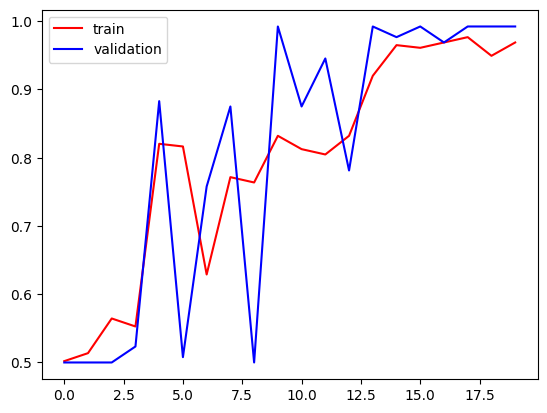

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

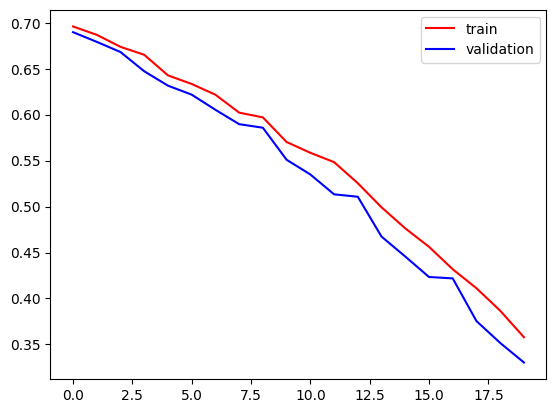

In [ ]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(256,256),
    batch_size=32,
    class_mode='binary'
)

Found 160 images belonging to 2 classes.


In [ ]:
predictions = model.predict(test_data)

5/5 ━━━━━━━━━━━━━━━━━━━━ 37s 7s/step


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report


true_labels = test_data.classes
predicted_labels = (predictions > 0.5).astype(int)

cm = confusion_matrix(true_labels, predicted_labels)

print("Confusion Matrix:")
print(cm)

print("Classification Report:")
print(classification_report(true_labels, predicted_labels))

Confusion Matrix:
[[42 38]
 [40 40]]
Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.53      0.52        80
           1       0.51      0.50      0.51        80

    accuracy                           0.51       160
   macro avg       0.51      0.51      0.51       160
weighted avg       0.51      0.51      0.51       160



**Pre-trained Model VGG16**

In [ ]:
import tensorflow as tf
from keras import Sequential
from keras.layers import Dense, Flatten

tf.keras.backend.clear_session()

vgg_model = Sequential()

pretrained_model = tf.keras.applications.VGG16(
    include_top=False,
    input_shape=(256, 256, 3),
    pooling='avg',
    weights='imagenet'
)

for layer in pretrained_model.layers:
    layer.trainable = False

vgg_model.add(pretrained_model)
vgg_model.add(Flatten())
vgg_model.add(Dense(256, activation='relu'))
vgg_model.add(Dense(1, activation='sigmoid'))

In [ ]:
from keras.optimizers import Adam
vgg_model.compile(optimizer=Adam(learning_rate=0.001),loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
history = vgg_model.fit(train_data, epochs=20, validation_data=validation_data)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 573s 36s/step - accuracy: 0.5615 - loss: 0.6813 - val_accuracy: 0.7109 - val_loss: 0.6273
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 526s 33s/step - accuracy: 0.7816 - loss: 0.5763 - val_accuracy: 0.7266 - val_loss: 0.5937
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 530s 33s/step - accuracy: 0.8131 - loss: 0.4889 - val_accuracy: 0.7266 - val_loss: 0.5342
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 529s 33s/step - accuracy: 0.8094 - loss: 0.4545 - val_accuracy: 0.7891 - val_loss: 0.4850
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 530s 33s/step - accuracy: 0.9068 - loss: 0.3538 - val_accuracy: 0.8125 - val_loss: 0.4428
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 578s 37s/step - accuracy: 0.8946 - loss: 0.3122 - val_accuracy: 0.9062 - val_loss: 0.3948
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 565s 36s/step - accuracy: 0.9601 - loss: 0.2516 - val_accuracy: 0.9141 - val_loss: 0.3552
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 565s 36s/step - accuracy: 0.9851 - loss: 0.2044 - val_accuracy: 0.

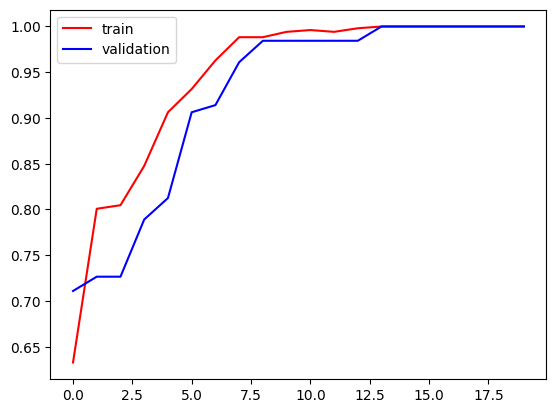

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

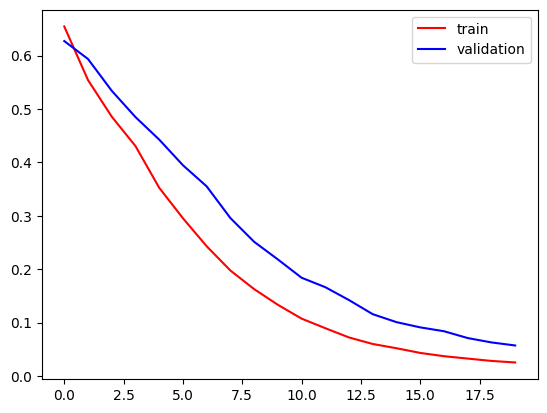

In [ ]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(256,256),
    batch_size=32,
    class_mode='binary'
)

Found 160 images belonging to 2 classes.


In [ ]:
predictions = vgg_model.predict(test_data)

5/5 ━━━━━━━━━━━━━━━━━━━━ 132s 26s/step


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

true_labels = test_data.classes
predicted_labels = (predictions > 0.5).astype(int)

cm = confusion_matrix(true_labels, predicted_labels)

print("Confusion Matrix:")
print(cm)

print("Classification Report:")
print(classification_report(true_labels, predicted_labels))

Confusion Matrix:
[[38 42]
 [42 38]]
Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.47      0.47        80
           1       0.47      0.47      0.47        80

    accuracy                           0.47       160
   macro avg       0.47      0.47      0.47       160
weighted avg       0.47      0.47      0.47       160



**Combining ResNet and MobileNetV2 models **

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224,224),
    batch_size=32,
    class_mode='binary',
    subset='training'
)

validation_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

validation_data = validation_datagen.flow_from_directory(
    train_dir,
    target_size=(224,224),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

Found 512 images belonging to 2 classes.
Found 128 images belonging to 2 classes.


In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Flatten, Dropout, BatchNormalization, Concatenate
from keras.models import Model

tf.keras.backend.clear_session()

print("=== Building Combined ResNet50 + MobileNetV2 Model ===")
print("Note: Using 224x224 input size for compatibility")

resnet_base = tf.keras.applications.ResNet50(
    include_top=False,
    input_shape=(224, 224, 3),
    pooling='avg',
    weights='imagenet'
)

mobilenet_base = tf.keras.applications.MobileNetV2(
    include_top=False,
    input_shape=(224, 224, 3),
    pooling='avg',
    weights='imagenet',
    alpha=1.0
)

for layer in resnet_base.layers:
    layer.trainable = False

for layer in mobilenet_base.layers:
    layer.trainable = False


combined_model = Sequential(name="Combined_ResNet_MobileNet")


combined_model.add(tf.keras.layers.Input(shape=(224, 224, 3)))

print("Adding ResNet50 branch...")
combined_model.add(resnet_base)
combined_model.add(Flatten())
combined_model.add(Dense(512, activation='relu'))
combined_model.add(BatchNormalization())
combined_model.add(Dropout(0.5))
combined_model.add(Dense(256, activation='relu'))
combined_model.add(BatchNormalization())
combined_model.add(Dropout(0.5))

resnet_output = combined_model.layers[-1].output


print("Adding MobileNetV2 branch...")

mobilenet_input = tf.keras.layers.Input(shape=(224, 224, 3))
x = mobilenet_base(mobilenet_input)
x = Flatten()(x)
x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
x = Dense(128, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
mobilenet_output = x


mobilenet_branch = Model(inputs=mobilenet_input, outputs=mobilenet_output)

print("Combining branches...")


final_input = tf.keras.layers.Input(shape=(224, 224, 3))


resnet_features = resnet_base(final_input)
resnet_features = Flatten()(resnet_features)
resnet_features = Dense(512, activation='relu')(resnet_features)
resnet_features = BatchNormalization()(resnet_features)
resnet_features = Dropout(0.5)(resnet_features)
resnet_features = Dense(256, activation='relu')(resnet_features)
resnet_features = BatchNormalization()(resnet_features)
resnet_features = Dropout(0.5)(resnet_features)


mobilenet_features = mobilenet_base(final_input)
mobilenet_features = Flatten()(mobilenet_features)
mobilenet_features = Dense(256, activation='relu')(mobilenet_features)
mobilenet_features = BatchNormalization()(mobilenet_features)
mobilenet_features = Dropout(0.5)(mobilenet_features)
mobilenet_features = Dense(128, activation='relu')(mobilenet_features)
mobilenet_features = BatchNormalization()(mobilenet_features)
mobilenet_features = Dropout(0.5)(mobilenet_features)


combined_features = Concatenate()([resnet_features, mobilenet_features])


x = Dense(256, activation='relu')(combined_features)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

x = Dense(128, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

x = Dense(64, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

output = Dense(1, activation='sigmoid')(x)


combined_model = Model(inputs=final_input, outputs=output)

print("✅ Combined ResNet50 + MobileNetV2 model created successfully!")

=== Building Combined ResNet50 + MobileNetV2 Model ===
Note: Using 224x224 input size for compatibility
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Adding ResNet50 branch...
Adding MobileNetV2 branch...
Combining branches...
✅ Combined ResNet50 + MobileNetV2 model created successfully!


In [ ]:
from keras.optimizers import Adam
combined_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = combined_model.fit(train_data, epochs=20, validation_data=validation_data)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 211s 12s/step - accuracy: 0.4495 - loss: 0.9860 - val_accuracy: 0.5000 - val_loss: 0.7395
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 155s 10s/step - accuracy: 0.5269 - loss: 0.8880 - val_accuracy: 0.5156 - val_loss: 0.7020
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 171s 11s/step - accuracy: 0.5867 - loss: 0.8603 - val_accuracy: 0.5469 - val_loss: 0.6843
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 157s 10s/step - accuracy: 0.6356 - loss: 0.7361 - val_accuracy: 0.5000 - val_loss: 0.6812
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 158s 10s/step - accuracy: 0.6095 - loss: 0.7054 - val_accuracy: 0.5156 - val_loss: 0.6793
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 156s 10s/step - accuracy: 0.6724 - loss: 0.6317 - val_accuracy: 0.5078 - val_loss: 0.6730
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 212s 10s/step - accuracy: 0.6976 - loss: 0.5635 - val_accuracy: 0.5078 - val_loss: 0.6693
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 156s 10s/step - accuracy: 0.7828 - loss: 0.4681 - val_accuracy: 0.

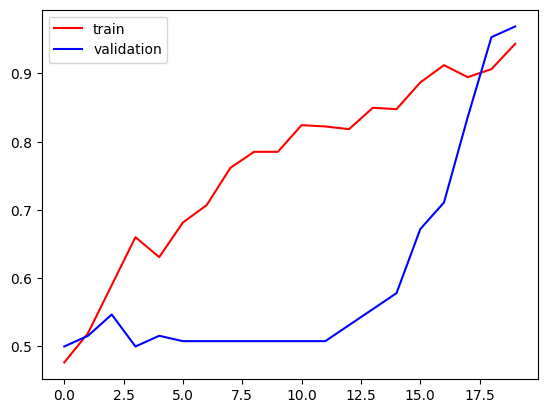

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

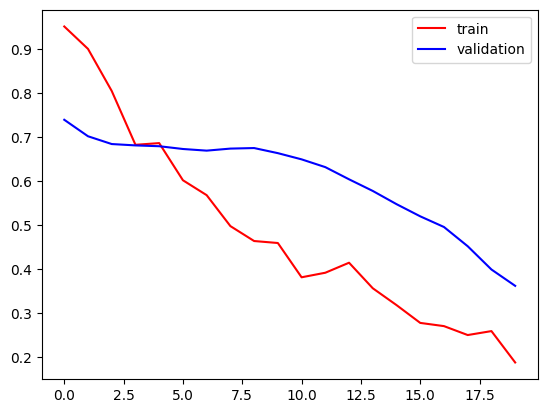

In [ ]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224,224),
    batch_size=32,
    class_mode='binary'
)

Found 160 images belonging to 2 classes.


In [ ]:
#predict the test data
predictions = combined_model.predict(test_data)

5/5 ━━━━━━━━━━━━━━━━━━━━ 62s 12s/step


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report


true_labels = test_data.classes
predicted_labels = (predictions > 0.5).astype(int)

cm = confusion_matrix(true_labels, predicted_labels)


print("Confusion Matrix:")
print(cm)

print("Classification Report:")
print(classification_report(true_labels, predicted_labels))

Confusion Matrix:
[[25 55]
 [27 53]]
Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.31      0.38        80
           1       0.49      0.66      0.56        80

    accuracy                           0.49       160
   macro avg       0.49      0.49      0.47       160
weighted avg       0.49      0.49      0.47       160



In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Flatten, Dropout, BatchNormalization, Concatenate
from keras.models import Model

tf.keras.backend.clear_session()

resnet_base = tf.keras.applications.ResNet50(
    include_top=False,
    input_shape=(224, 224, 3),
    pooling='avg',
    weights='imagenet'
)

mobilenet_base = tf.keras.applications.MobileNetV2(
    include_top=False,
    input_shape=(224, 224, 3),
    pooling='avg',
    weights='imagenet',
    alpha=1.0
)

for layer in resnet_base.layers:
    layer.trainable = False

for layer in mobilenet_base.layers:
    layer.trainable = False

final_input = tf.keras.layers.Input(shape=(224, 224, 3))

resnet_features = resnet_base(final_input)
resnet_features = Flatten()(resnet_features)


resnet_features = Dense(1024, activation='relu')(resnet_features)
resnet_features = BatchNormalization()(resnet_features)
resnet_features = Dropout(0.6)(resnet_features)

resnet_features = Dense(768, activation='relu')(resnet_features)
resnet_features = BatchNormalization()(resnet_features)
resnet_features = Dropout(0.6)(resnet_features)

resnet_features = Dense(512, activation='relu')(resnet_features)
resnet_features = BatchNormalization()(resnet_features)
resnet_features = Dropout(0.5)(resnet_features)

resnet_features = Dense(384, activation='relu')(resnet_features)
resnet_features = BatchNormalization()(resnet_features)
resnet_features = Dropout(0.5)(resnet_features)

resnet_features = Dense(256, activation='relu')(resnet_features)
resnet_features = BatchNormalization()(resnet_features)
resnet_features = Dropout(0.5)(resnet_features)

mobilenet_features = mobilenet_base(final_input)
mobilenet_features = Flatten()(mobilenet_features)

mobilenet_features = Dense(1024, activation='relu')(mobilenet_features)
mobilenet_features = BatchNormalization()(mobilenet_features)
mobilenet_features = Dropout(0.6)(mobilenet_features)

mobilenet_features = Dense(768, activation='relu')(mobilenet_features)
mobilenet_features = BatchNormalization()(mobilenet_features)
mobilenet_features = Dropout(0.6)(mobilenet_features)

mobilenet_features = Dense(512, activation='relu')(mobilenet_features)
mobilenet_features = BatchNormalization()(mobilenet_features)
mobilenet_features = Dropout(0.5)(mobilenet_features)

mobilenet_features = Dense(384, activation='relu')(mobilenet_features)
mobilenet_features = BatchNormalization()(mobilenet_features)
mobilenet_features = Dropout(0.5)(mobilenet_features)

mobilenet_features = Dense(256, activation='relu')(mobilenet_features)
mobilenet_features = BatchNormalization()(mobilenet_features)
mobilenet_features = Dropout(0.5)(mobilenet_features)


print("\nCombining branches...")

combined_features = Concatenate()([resnet_features, mobilenet_features])
print(f"Combined feature size: {combined_features.shape}")

# Layer 1
x = Dense(1024, activation='relu')(combined_features)
x = BatchNormalization()(x)
x = Dropout(0.6)(x)

# Layer 2
x = Dense(768, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.6)(x)

# Layer 3
x = Dense(512, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

# Layer 4
x = Dense(384, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

# Layer 5
x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

# Layer 6
x = Dense(192, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)

# Layer 7
x = Dense(128, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)

# Layer 8
x = Dense(64, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

# Layer 9 (Additional layer)
x = Dense(32, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

# Output layer
output = Dense(1, activation='sigmoid')(x)


enhanced_combined_model = Model(inputs=final_input, outputs=output, name="Enhanced_Combined_ResNet_MobileNet")


Combining branches...
Combined feature size: (None, 512)


In [ ]:
from keras.optimizers import Adam
enhanced_combined_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = enhanced_combined_model.fit(train_data, epochs=20, validation_data=validation_data)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 184s 10s/step - accuracy: 0.4748 - loss: 0.9117 - val_accuracy: 0.5000 - val_loss: 0.6937
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 143s 9s/step - accuracy: 0.5005 - loss: 0.8736 - val_accuracy: 0.5000 - val_loss: 0.6954
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 144s 9s/step - accuracy: 0.4874 - loss: 0.8733 - val_accuracy: 0.5000 - val_loss: 0.6974
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 143s 9s/step - accuracy: 0.4677 - loss: 0.9167 - val_accuracy: 0.5000 - val_loss: 0.7003
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 140s 9s/step - accuracy: 0.5187 - loss: 0.8677 - val_accuracy: 0.5000 - val_loss: 0.7045
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 142s 9s/step - accuracy: 0.4883 - loss: 0.8298 - val_accuracy: 0.5000 - val_loss: 0.7107
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 142s 9s/step - accuracy: 0.5154 - loss: 0.8414 - val_accuracy: 0.5000 - val_loss: 0.7152
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 155s 10s/step - accuracy: 0.5066 - loss: 0.8682 - val_accuracy: 0.5000 -

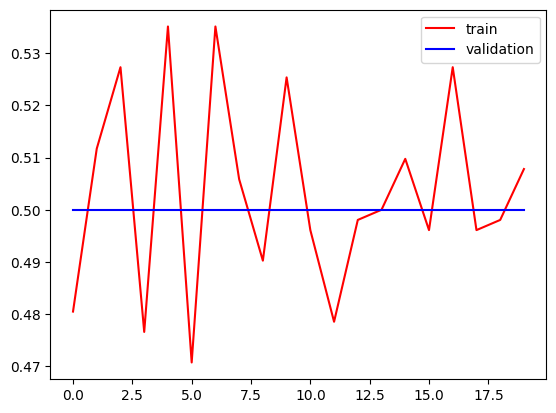

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

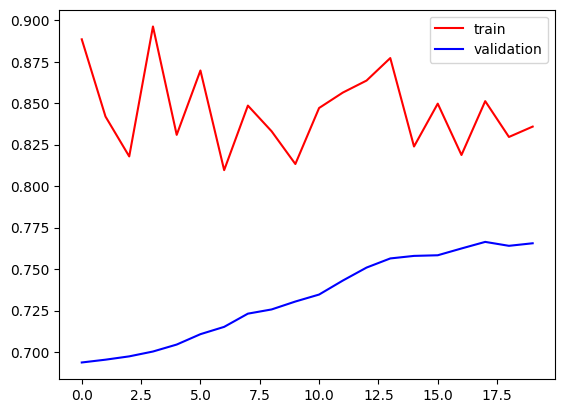

In [ ]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224,224),
    batch_size=32,
    class_mode='binary'
)

Found 160 images belonging to 2 classes.


In [ ]:
#predict the test data
predictions = combined_model.predict(test_data)

5/5 ━━━━━━━━━━━━━━━━━━━━ 37s 7s/step


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

true_labels = test_data.classes
predicted_labels = (predictions > 0.5).astype(int)

cm = confusion_matrix(true_labels, predicted_labels)

print("Confusion Matrix:")
print(cm)

print("Classification Report:")
print(classification_report(true_labels, predicted_labels))

Confusion Matrix:
[[38 42]
 [35 45]]
Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.47      0.50        80
           1       0.52      0.56      0.54        80

    accuracy                           0.52       160
   macro avg       0.52      0.52      0.52       160
weighted avg       0.52      0.52      0.52       160



**Pretrained Model VGG16**

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator


train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rescale=1./255,
    validation_split=0.2
)

train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(256,256),
    batch_size=32,
    class_mode='binary',
    subset='training'
)


validation_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)


validation_data = validation_datagen.flow_from_directory(
    train_dir,
    target_size=(256,256),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

Found 512 images belonging to 2 classes.
Found 128 images belonging to 2 classes.


In [ ]:
import tensorflow as tf
from keras import Sequential
from keras.layers import Dense, Flatten, Dropout, BatchNormalization

tf.keras.backend.clear_session()

vgg_model = Sequential()

pretrained_model = tf.keras.applications.VGG16(
    include_top=False,
    input_shape=(256, 256, 3),
    pooling='avg',
    weights='imagenet'
)

for layer in pretrained_model.layers:
    layer.trainable = False

vgg_model.add(pretrained_model)
vgg_model.add(Flatten())
vgg_model.add(Dense(512, activation='relu'))
vgg_model.add(BatchNormalization())
vgg_model.add(Dropout(0.5))
vgg_model.add(Dense(256, activation='relu'))
vgg_model.add(BatchNormalization())
vgg_model.add(Dropout(0.5))
vgg_model.add(Dense(128, activation='relu'))
vgg_model.add(BatchNormalization())
vgg_model.add(Dropout(0.5))
vgg_model.add(Dense(1, activation='sigmoid'))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
from keras.optimizers import Adam
vgg_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = vgg_model.fit(train_data, epochs=20, validation_data=validation_data)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 497s 31s/step - accuracy: 0.5160 - loss: 0.9738 - val_accuracy: 0.5000 - val_loss: 0.7411
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 453s 29s/step - accuracy: 0.7061 - loss: 0.6148 - val_accuracy: 0.5000 - val_loss: 0.7014
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 504s 32s/step - accuracy: 0.8152 - loss: 0.4057 - val_accuracy: 0.5000 - val_loss: 0.6802
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 452s 29s/step - accuracy: 0.8142 - loss: 0.4279 - val_accuracy: 0.5000 - val_loss: 0.6753
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 453s 29s/step - accuracy: 0.8611 - loss: 0.2991 - val_accuracy: 0.5000 - val_loss: 0.6780
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 503s 32s/step - accuracy: 0.8820 - loss: 0.2756 - val_accuracy: 0.5000 - val_loss: 0.6874
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 452s 29s/step - accuracy: 0.9132 - loss: 0.2142 - val_accuracy: 0.5000 - val_loss: 0.6961
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 454s 29s/step - accuracy: 0.9317 - loss: 0.1655 - val_accuracy: 0.

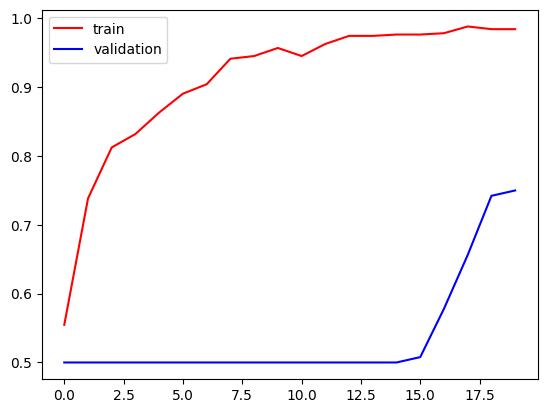

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

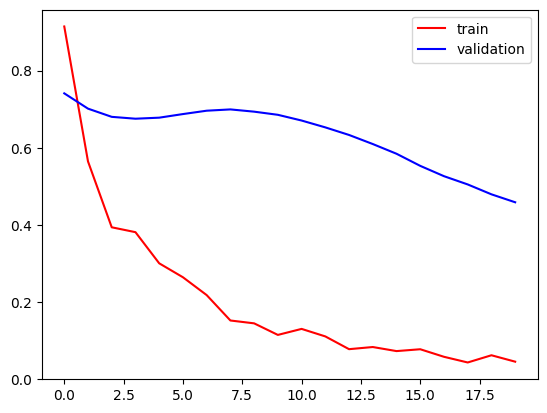

In [ ]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(256,256),
    batch_size=32,
    class_mode='binary'
)

Found 160 images belonging to 2 classes.


In [ ]:
#predict the test data
predictions = vgg_model.predict(test_data)

5/5 ━━━━━━━━━━━━━━━━━━━━ 121s 25s/step


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Assuming you have ground truth labels (true_labels) and predicted labels (predictions)
true_labels = test_data.classes
predicted_labels = (predictions > 0.5).astype(int)  # Adjust the threshold as needed

# Calculate confusion matrix
cm = confusion_matrix(true_labels, predicted_labels)

# Print confusion matrix
print("Confusion Matrix:")
print(cm)

# Print classification report
print("Classification Report:")
print(classification_report(true_labels, predicted_labels))

Confusion Matrix:
[[53 27]
 [55 25]]
Classification Report:
              precision    recall  f1-score   support

           0       0.49      0.66      0.56        80
           1       0.48      0.31      0.38        80

    accuracy                           0.49       160
   macro avg       0.49      0.49      0.47       160
weighted avg       0.49      0.49      0.47       160

